# Week 04 · Policy Iteration: Jack's Car Rental — 정책 반복과 잭의 렌터카 문제

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/narame7/UOS-Reinforcement-Learning/blob/main/week04_dynamic_programming/02_policy_iteration_jacks_car_rental.ipynb)

슬라이드 **"Jack's Car Rental"**, **"Poisson Distribution"**, **"Policy Iteration in Jack's Car Rental"**(= Sutton & Barto Figure 4.2)를 재현하고,
**"Policy Improvement"**, **"Modified Policy Iteration"**, **"Generalized Policy Iteration"**, **"Value Iteration"**,
**"Approximate Dynamic Programming"**(Fitted Value Iteration)을 같은 문제에서 실행해 봅니다.
정책 $\pi_0\to\pi_4$와 $v_{\pi_4}$가 그림처럼 나오는지, 평가를 끝까지 하지 않아도 되는지, 가치 함수를 15개 파라미터로 근사해도 되는지 확인합니다.

In [1]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# 공통 플롯 스타일 (모든 주차 노트북 동일)
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
SEQ_CMAP = LinearSegmentedColormap.from_list("seq_blue", ["#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#0d366b"])
DIV_CMAP = LinearSegmentedColormap.from_list("div_blue_red", ["#1c5cab", "#86b6ef", "#f0efec", "#f0a09f", "#b8302f"])
mpl.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.prop_cycle": mpl.cycler(color=PALETTE),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#0b0b0b", "text.color": "#0b0b0b",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.8,
    "lines.linewidth": 2, "legend.frameon": False, "font.size": 10,
    "axes.titlesize": 11, "axes.titleweight": "bold",
})
np.set_printoptions(precision=2, suppress=True)
rng = np.random.default_rng(0)

# 이번 주 추가 import
import math
import time
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.collections import LineCollection

## 1. 문제 설정 (Jack's Car Rental, Poisson Distribution)

Sutton & Barto Example 4.2의 설정을 그대로 씁니다.

- **상태**: 하루 영업이 끝난 저녁, 두 영업소의 차량 수 $(n_1, n_2)$, 각각 $0\sim 20$대 → $21\times 21 = 441$개 상태.
- **행동**: 밤사이 1번 → 2번 영업소로 옮기는 차량 수 $a\in\{-5,\dots,5\}$ (음수는 2번 → 1번). 옮길 차가 있어야 가능($a\le n_1$, $-a\le n_2$).
- **보상**: 대여 1대당 $+\$10$, 이동 1대당 $-\$2$.
- **전이**: 다음 날 대여 요청과 반납 대수가 포아송 분포(Poisson distribution) $P(k)=\frac{\lambda^k}{k!}e^{-\lambda}$를 따름.
  요청 $\lambda=3$ (1번), $4$ (2번) / 반납 $\lambda=3$ (1번), $2$ (2번). 반납된 차는 **다음 날부터** 대여 가능.
- 영업소당 최대 20대(넘치는 차는 본사로 반납되어 사라짐), $\gamma=0.9$, 연속(continuing) MDP.

하루의 순서: 저녁 $(n_1,n_2)$ → 밤에 $a$대 이동 (비용 $2|a|$) → 아침 $(m_1,m_2)=(\min(n_1-a,20),\ \min(n_2+a,20))$
→ 낮에 대여 $\min(\text{요청}, m_i)$대 (수익 $10\times$대여) → 반납 추가 (최대 20) → 다음 저녁 $(n_1', n_2')$.

두 영업소는 아침 차량 수가 정해지면 서로 **독립**입니다. 그래서 영업소별로 $21\times 21$ 전이 행렬 $P_i[m, n']$과
기대 대여 수익 $R_i[m]$만 미리 계산해 두면 됩니다. 포아송 꼬리를 자르지 않고, "요청이 $m$대 이상"과 "반납 후 20대 이상"의 확률을
정확히 한 칸에 모읍니다.

In [2]:
MAX_CARS = 20
MAX_MOVE = 5
RENTAL_CREDIT = 10.0
MOVE_COST = 2.0
GAMMA = 0.9
LAMBDA_REQUEST = (3, 4)      # (1번, 2번 영업소)
LAMBDA_RETURN = (3, 2)
N = MAX_CARS + 1             # 차량 수 0..20
ACTIONS = np.arange(-MAX_MOVE, MAX_MOVE + 1)   # a > 0 : 1번 -> 2번


def poisson_pmf(lam, n_max):
    """P(X = k), k = 0..n_max."""
    return np.array([lam ** k * math.exp(-lam) / math.factorial(k) for k in range(n_max + 1)])


def location_model(lam_request, lam_return):
    """한 영업소의 하루.  P[m, n'] = P(저녁 n'대 | 아침 m대),  R[m] = 기대 대여 수익."""
    P = np.zeros((N, N))
    R = np.zeros(N)
    p_req = poisson_pmf(lam_request, MAX_CARS)
    p_ret = poisson_pmf(lam_return, MAX_CARS)
    for m in range(N):
        # 대여 대수 = min(요청, m):  j < m 이면 P(요청 = j),  j = m 이면 P(요청 >= m)
        p_rent = np.append(p_req[:m], 1.0 - p_req[:m].sum())
        R[m] = RENTAL_CREDIT * np.dot(np.arange(m + 1), p_rent)
        for rented, pr in enumerate(p_rent):
            left = m - rented
            for ret in range(MAX_CARS - left):                        # 반납 후 20대 미만
                P[m, left + ret] += pr * p_ret[ret]
            P[m, MAX_CARS] += pr * (1.0 - p_ret[:MAX_CARS - left].sum())  # 20대 이상 -> 20
    return P, R


P1, R1 = location_model(LAMBDA_REQUEST[0], LAMBDA_RETURN[0])
P2, R2 = location_model(LAMBDA_REQUEST[1], LAMBDA_RETURN[1])
print("각 행의 확률 합 = 1 ?", np.allclose(P1.sum(1), 1), np.allclose(P2.sum(1), 1))
print("R1[m], m=0..5:", R1[:6])
print("R2[m], m=0..5:", R2[:6])

각 행의 확률 합 = 1 ? True True
R1[m], m=0..5: [ 0.    9.5  17.51 23.28 26.81 28.65]
R2[m], m=0..5: [ 0.    9.82 18.9  26.52 32.19 35.9 ]


포아송 분포와, 영업소별 모델이 무엇을 뜻하는지 그려 봅니다. 가운데 그림: 차가 많을수록 기대 수익은 $10\lambda_{\text{req}}$에 포화됩니다.
오른쪽 그림: 하루 동안의 기대 순변화 $\mathbb{E}[n'-m]$. 2번 영업소는 요청(4)이 반납(2)보다 많아 차가 **줄어드는** 경향이 있으므로
1번에서 2번으로 차를 옮기는 정책이 나올 것이라 예상할 수 있습니다.

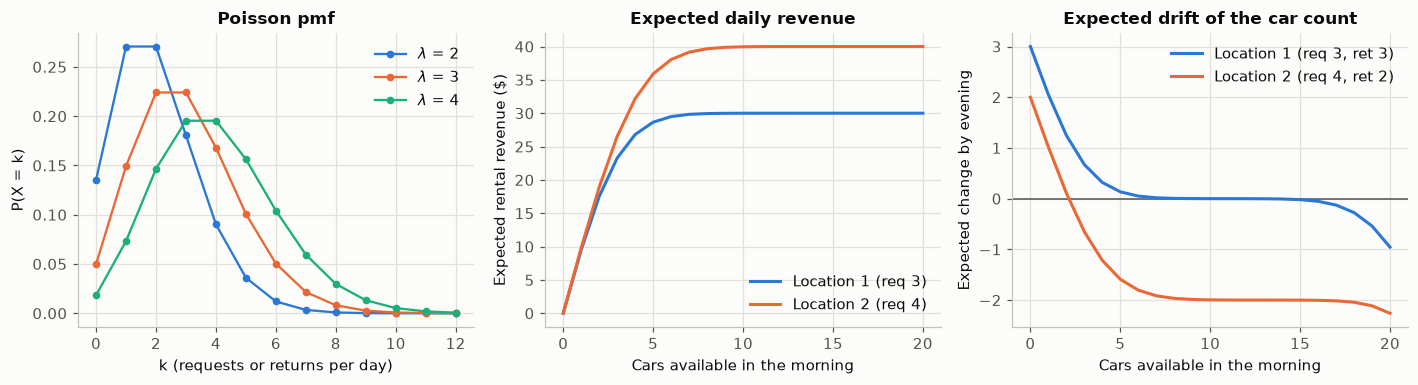

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
ks = np.arange(13)
for i, lam in enumerate([2, 3, 4]):
    axes[0].plot(ks, poisson_pmf(lam, 12), "o-", ms=4, lw=1.5, color=PALETTE[i], label=rf"$\lambda$ = {lam}")
axes[0].set_xlabel("k (requests or returns per day)"); axes[0].set_ylabel("P(X = k)")
axes[0].set_title("Poisson pmf"); axes[0].legend()

m = np.arange(N)
axes[1].plot(m, R1, color=PALETTE[0], label="Location 1 (req 3)")
axes[1].plot(m, R2, color=PALETTE[1], label="Location 2 (req 4)")
axes[1].set_xlabel("Cars available in the morning"); axes[1].set_ylabel("Expected rental revenue ($)")
axes[1].set_title("Expected daily revenue"); axes[1].legend()

axes[2].axhline(0, color="#52514e", lw=1)
axes[2].plot(m, P1 @ m - m, color=PALETTE[0], label="Location 1 (req 3, ret 3)")
axes[2].plot(m, P2 @ m - m, color=PALETTE[1], label="Location 2 (req 4, ret 2)")
axes[2].set_xlabel("Cars available in the morning"); axes[2].set_ylabel("Expected change by evening")
axes[2].set_title("Expected drift of the car count"); axes[2].legend()
plt.tight_layout(); plt.show()

### 전체 MDP를 배열 연산으로

상태 $(n_1,n_2)$에서 행동 $a$의 가치는

$$q(s,a) = -2|a| + \underbrace{R_1[m_1] + R_2[m_2] + \gamma \sum_{n_1',n_2'} P_1[m_1,n_1']\,P_2[m_2,n_2']\,V(n_1',n_2')}_{U[m_1, m_2]}$$

입니다. 밑줄 친 부분은 아침 차량 수 $(m_1,m_2)$에만 의존하고, 행렬로 쓰면 $U = R_1\mathbf{1}^\top + \mathbf{1}R_2^\top + \gamma\,P_1 V P_2^\top$
한 줄입니다. 모든 $(n_1,n_2,a)$에 대한 아침 차량 수 $(m_1,m_2)$를 인덱스 배열로 미리 만들어 두면, 441개 상태 × 11개 행동의
백업이 행렬 곱 두 번과 인덱싱으로 끝납니다.

In [4]:
n1_idx = np.arange(N)[:, None, None]
n2_idx = np.arange(N)[None, :, None]
a_idx = ACTIONS[None, None, :]
FEASIBLE = (a_idx <= n1_idx) & (-a_idx <= n2_idx)                  # (21, 21, 11)
M1 = np.broadcast_to(np.clip(n1_idx - a_idx, 0, MAX_CARS), FEASIBLE.shape)   # 아침 차량 수 (20 초과분은 사라짐)
M2 = np.broadcast_to(np.clip(n2_idx + a_idx, 0, MAX_CARS), FEASIBLE.shape)
COST = MOVE_COST * np.abs(ACTIONS)                                  # (11,)


def morning_value(V):
    """U[m1, m2] = R1[m1] + R2[m2] + gamma * E[V(n1', n2') | m1, m2]."""
    return R1[:, None] + R2[None, :] + GAMMA * P1 @ V @ P2.T


def q_values(V):
    """q[n1, n2, a] (불가능한 행동은 -inf)."""
    q = morning_value(V)[M1, M2] - COST
    return np.where(FEASIBLE, q, -np.inf)


def backup_policy(V, pi):
    """벨만 기대 백업 한 번 (동기식): (T^pi V)(s) = q(s, pi(s))."""
    a = pi + MAX_MOVE                                   # 행동 값 -> 인덱스
    m1 = np.take_along_axis(M1, a[..., None], axis=2)[..., 0]
    m2 = np.take_along_axis(M2, a[..., None], axis=2)[..., 0]
    return morning_value(V)[m1, m2] - MOVE_COST * np.abs(pi)


def evaluate_policy(pi, V, theta=1e-4, max_sweeps=10_000):
    """반복 정책 평가: max |V_new - V| < theta 가 될 때까지 스윕. (V, 스윕 수) 반환."""
    for sweep in range(1, max_sweeps + 1):
        V_new = backup_policy(V, pi)
        delta = np.abs(V_new - V).max()
        V = V_new
        if delta < theta:
            break
    return V, sweep


def improve_policy(V, pi_old, tol=1e-9):
    """탐욕적 정책 개선. 기존 행동이 최댓값과 동점이면 유지 (정책이 동점 사이를 오가며 끝나지 않는 문제 방지, 교재 연습문제 4.4)."""
    q = q_values(V)
    best = q.max(axis=2)
    q_old = np.take_along_axis(q, (pi_old + MAX_MOVE)[..., None], axis=2)[..., 0]
    pi_greedy = ACTIONS[np.argmax(q, axis=2)]
    return np.where(q_old >= best - tol, pi_old, pi_greedy)

## 2. 정책 반복 (Policy Iteration in Jack's Car Rental)

교재와 같이 "차를 전혀 옮기지 않는 정책" $\pi_0\equiv 0$, $V\equiv 0$에서 시작해 **평가 → 개선**을 반복합니다.
각 평가는 직전 정책의 $V$에서 시작합니다(warm start). 평가 종료 기준은 $\theta=10^{-4}$입니다.

In [5]:
t0 = time.perf_counter()
pi = np.zeros((N, N), dtype=int)
V = np.zeros((N, N))
policies, values = [pi], []
print("iter | eval sweeps | changed states | min V   | max V")
for it in range(20):
    V, n_sweeps = evaluate_policy(pi, V)
    values.append(V)
    pi_new = improve_policy(V, pi)
    n_changed = int((pi_new != pi).sum())
    print(f"{it:4d} | {n_sweeps:11d} | {n_changed:14d} | {V.min():7.1f} | {V.max():6.1f}")
    if n_changed == 0:
        break
    pi = pi_new
    policies.append(pi)
print(f"policy iteration finished in {time.perf_counter() - t0:.3f} s  ->  pi_{len(policies) - 1} is stable")

iter | eval sweeps | changed states | min V   | max V
   0 |         126 |            318 |   407.2 |  611.4
   1 |          91 |            272 |   418.4 |  627.3
   2 |          80 |             79 |   421.3 |  636.7
   3 |          45 |              8 |   421.4 |  637.0
   4 |          14 |              0 |   421.4 |  637.0
policy iteration finished in 0.008 s  ->  pi_4 is stable


교재 그림과 같은 방식으로 그립니다: 가로축 = 2번 영업소 차량 수, 세로축 = 1번 영업소 차량 수, 색 = 옮기는 차량 수
(빨강: 1번→2번, 파랑: 2번→1번). 같은 행동 영역의 경계에 선을 긋고 영역마다 행동 값을 적었습니다.

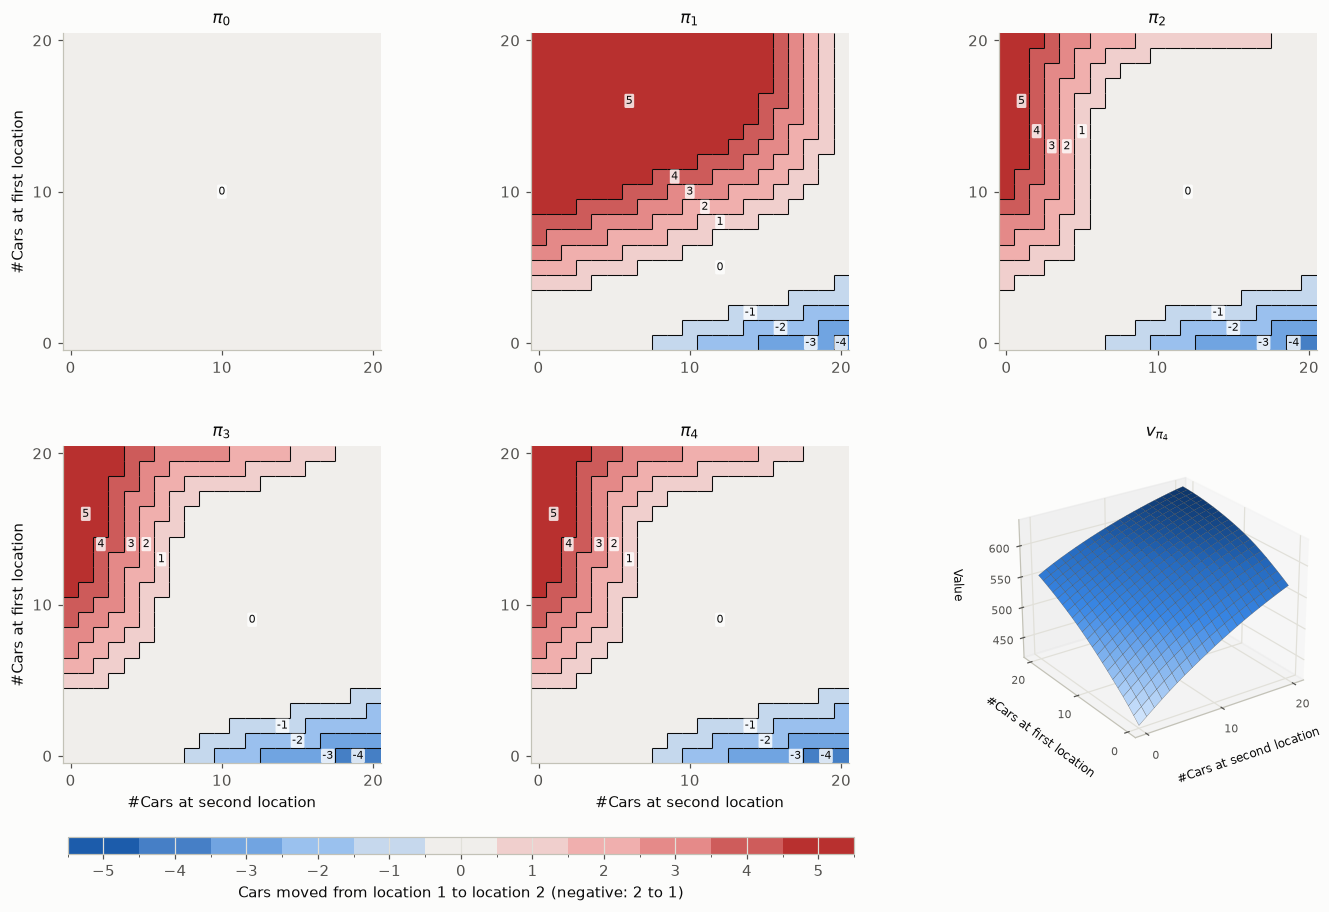

In [6]:
POLICY_CMAP = ListedColormap(DIV_CMAP(np.linspace(0, 1, 2 * MAX_MOVE + 1)))
POLICY_NORM = BoundaryNorm(np.arange(-MAX_MOVE - 0.5, MAX_MOVE + 1.5), POLICY_CMAP.N)


def draw_car_policy(ax, pi, title=""):
    """정책 히트맵 + 행동 영역 경계선(계단 모양) + 영역 라벨."""
    ax.imshow(pi, origin="lower", cmap=POLICY_CMAP, norm=POLICY_NORM,
              extent=(-0.5, MAX_CARS + 0.5, -0.5, MAX_CARS + 0.5))
    segs = []
    for i in range(N):              # i = n1 (세로축)
        for j in range(N):          # j = n2 (가로축)
            if j + 1 < N and pi[i, j] != pi[i, j + 1]:
                segs.append([(j + 0.5, i - 0.5), (j + 0.5, i + 0.5)])
            if i + 1 < N and pi[i, j] != pi[i + 1, j]:
                segs.append([(j - 0.5, i + 0.5), (j + 0.5, i + 0.5)])
    ax.add_collection(LineCollection(segs, colors="#0b0b0b", linewidths=0.7))
    for act in np.unique(pi):
        ii, jj = np.nonzero(pi == act)
        k = np.argmin((ii - ii.mean()) ** 2 + (jj - jj.mean()) ** 2)   # 영역 중심에 가장 가까운 칸
        ax.text(jj[k], ii[k], str(act), ha="center", va="center", fontsize=7.5,
                bbox=dict(boxstyle="round,pad=0.12", fc="white", ec="none", alpha=0.8))
    ax.set_xlim(-0.5, MAX_CARS + 0.5); ax.set_ylim(-0.5, MAX_CARS + 0.5)
    ax.set_xticks([0, 10, 20]); ax.set_yticks([0, 10, 20])
    ax.grid(False)
    ax.set_title(title)


fig = plt.figure(figsize=(13, 8.2))
fig.subplots_adjust(left=0.06, right=0.97, bottom=0.14, top=0.95, wspace=0.28, hspace=0.3)
for k, p in enumerate(policies[:5]):
    ax = fig.add_subplot(2, 3, k + 1)
    draw_car_policy(ax, p, rf"$\pi_{k}$")
    if k in (0, 3):
        ax.set_ylabel("#Cars at first location")
    if k >= 3:
        ax.set_xlabel("#Cars at second location")
ax3d = fig.add_subplot(2, 3, 6, projection="3d")
X, Y = np.meshgrid(np.arange(N), np.arange(N))      # X = n2, Y = n1
ax3d.plot_surface(X, Y, values[4], cmap=SEQ_CMAP, edgecolor="#3a3a38", linewidth=0.15, antialiased=True)
ax3d.set_xlabel("#Cars at second location", fontsize=8, labelpad=2)
ax3d.set_ylabel("#Cars at first location", fontsize=8, labelpad=2)
ax3d.set_zlabel("Value", fontsize=8, labelpad=4)
ax3d.set_xticks([0, 10, 20]); ax3d.set_yticks([0, 10, 20]); ax3d.set_zticks([450, 500, 550, 600])
ax3d.tick_params(labelsize=7, pad=0)
ax3d.view_init(elev=25, azim=-125)
ax3d.set_title(r"$v_{\pi_4}$")
cax = fig.add_axes([0.08, 0.04, 0.55, 0.018])
cb = fig.colorbar(mpl.cm.ScalarMappable(norm=POLICY_NORM, cmap=POLICY_CMAP), cax=cax, orientation="horizontal",
                  ticks=ACTIONS)
cb.set_label("Cars moved from location 1 to location 2 (negative: 2 to 1)")
plt.show()

### 슬라이드와 비교

슬라이드의 그림(교재 Figure 4.2)은 숫자 표가 아니라 등고선 그림이므로 특징을 비교합니다.

- 정책 반복은 $\pi_0\to\pi_1\to\dots\to\pi_4$ 다섯 개의 정책을 만들고 $\pi_4$에서 멈춥니다(그림의 패널 수와 같음).
- $\pi_1$은 왼쪽 위 넓은 영역이 $5$, 오른쪽 아래 모서리가 $-1\sim-4$. $\pi_2\sim\pi_4$에서는 $5$ 영역이 왼쪽 가장자리로 좁아지고, 가운데가 넓은 $0$ 영역입니다.
- 모든 $\pi_1\sim\pi_4$에서 행동 범위가 $-4\sim5$ (그림에 $-5$ 영역은 없음).
- $v_{\pi_4}$ 그림의 세로축 눈금은 420과 612입니다. 곡면은 $(0,0)$에서 가장 낮고 $(20,20)$에서 가장 높습니다.

In [7]:
print("정책 개수 (pi_0 ... pi_K):", len(policies))
for k, p in enumerate(policies):
    print(f"pi_{k}: 행동 범위 [{p.min():+d}, {p.max():+d}],  행동 5 칸 수 = {(p == 5).sum():3d},  행동 0 칸 수 = {(p == 0).sum():3d}")
v4 = values[4]
i_min, i_max = np.unravel_index(v4.argmin(), v4.shape), np.unravel_index(v4.argmax(), v4.shape)
print(f"v_pi4: min = {v4.min():.1f} at (n1, n2) = ({i_min[0]}, {i_min[1]}),  "
      f"max = {v4.max():.1f} at (n1, n2) = ({i_max[0]}, {i_max[1]})   (그림 축 눈금: 420, 612)")
assert len(policies) == 5                                   # pi_0 ... pi_4, pi_4 stable
assert all(p.min() == -4 and p.max() == 5 for p in policies[1:])
assert abs(v4.min() - 420) < 5 and abs(v4.max() - 612) / 612 < 0.05

정책 개수 (pi_0 ... pi_K): 5
pi_0: 행동 범위 [+0, +0],  행동 5 칸 수 =   0,  행동 0 칸 수 = 441
pi_1: 행동 범위 [-4, +5],  행동 5 칸 수 = 149,  행동 0 칸 수 = 123
pi_2: 행동 범위 [-4, +5],  행동 5 칸 수 =  21,  행동 0 칸 수 = 287
pi_3: 행동 범위 [-4, +5],  행동 5 칸 수 =  27,  행동 0 칸 수 = 268
pi_4: 행동 범위 [-4, +5],  행동 5 칸 수 =  26,  행동 0 칸 수 = 270
v_pi4: min = 421.4 at (n1, n2) = (0, 0),  max = 637.0 at (n1, n2) = (20, 20)   (그림 축 눈금: 420, 612)


다섯 개의 정책과 $v_{\pi_4}$ 곡면 모양이 교재 그림과 같습니다. 가치의 최솟값 421.4는 그림의 420과 맞지만, 최댓값 637.0은
그림 눈금 612보다 약 4% 큽니다. 정책 $\pi_0\sim\pi_4$가 모두 그림과 같으므로 모델 자체보다는 교재 그림을 만든 원래 코드의 세부 처리
(포아송 꼬리를 어디서 자르는지 등)의 차이로 보입니다. 예를 들어 널리 쓰이는 재현 코드처럼 요청·반납 분포를 11대에서 자르고
나머지 확률을 버리면 범위가 약 406~618로 바뀝니다. 여기서는 꼬리를 자르지 않은 정확한 모델을 씁니다.

1번 영업소에 차가 많고 2번에 적을수록 많이 옮기며(빨강),
2번이 요청은 많고 반납은 적어 차가 부족해지기 쉬우므로 1번→2번 이동이 반대 방향보다 훨씬 넓게 나타납니다.
정책 반복 전체가 1초도 걸리지 않는 것은 전이를 $P_1, P_2$ 두 개의 작은 행렬로 분해해 벡터화했기 때문입니다.

## 3. 정책 개선 정리 확인 (Policy Improvement, Policy Improvement (2))

슬라이드의 정리: 탐욕적으로 개선한 정책 $\pi'$는 **모든 상태에서** $v_{\pi'}(s)\ge v_\pi(s)$이고,
개선이 멈추면 벨만 최적 방정식 $v_\pi(s)=\max_a q_\pi(s,a)$가 성립해 $\pi$가 최적입니다. 두 가지를 수치로 확인합니다.
($v_{\pi_k}$는 $\theta=10^{-4}$로 평가한 근사값이므로 비교에 $10^{-3}$의 여유를 둡니다.)

v_pi1 - v_pi0:  min =   8.4936,  mean =  20.67,  max =  75.13
v_pi2 - v_pi1:  min =   2.9611,  mean =   6.88,  max =  12.60
v_pi3 - v_pi2:  min =   0.0694,  mean =   0.18,  max =   0.79
v_pi4 - v_pi3:  min =   0.0006,  mean =   0.00,  max =   0.04


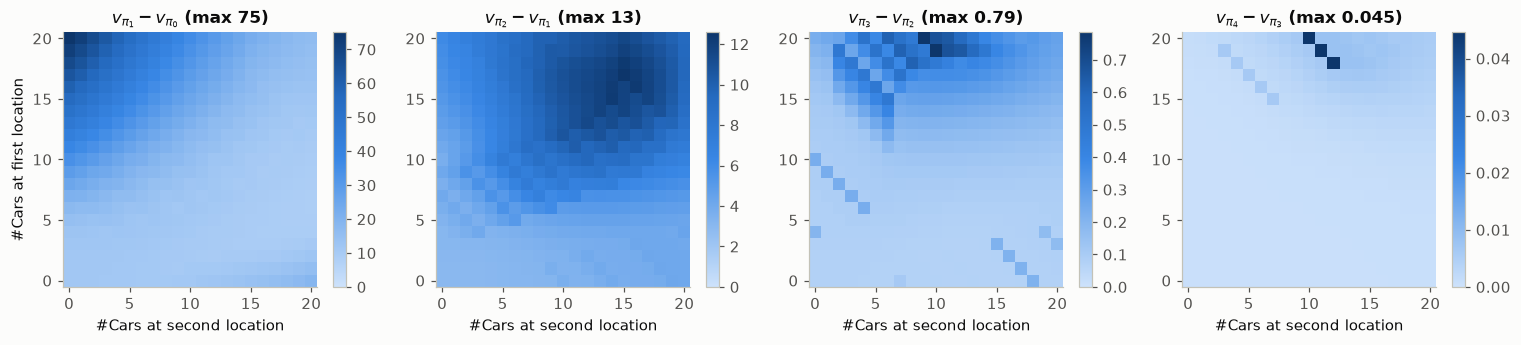

pi_4에서 벨만 최적 방정식 잔차 max_s |max_a q(s,a) - v(s)| = 6.12e-05


In [8]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.3))
gains = [values[k + 1] - values[k] for k in range(4)]
for k, g in enumerate(gains):
    print(f"v_pi{k+1} - v_pi{k}:  min = {g.min():8.4f},  mean = {g.mean():6.2f},  max = {g.max():6.2f}")
    assert g.min() > -1e-3                                     # 모든 상태에서 개선 (또는 동일)
    im = axes[k].imshow(g, origin="lower", cmap=SEQ_CMAP, vmin=0, vmax=g.max())
    fig.colorbar(im, ax=axes[k], shrink=0.8)
    axes[k].set_title(rf"$v_{{\pi_{k+1}}} - v_{{\pi_{k}}}$ (max {g.max():.2g})")
    axes[k].set_xlabel("#Cars at second location"); axes[k].grid(False)
axes[0].set_ylabel("#Cars at first location")
plt.tight_layout(); plt.show()

residual = np.abs(q_values(v4).max(axis=2) - v4).max()
print(f"pi_4에서 벨만 최적 방정식 잔차 max_s |max_a q(s,a) - v(s)| = {residual:.2e}")
assert residual < 1e-3

개선량은 모든 상태에서 0 이상이고(정리와 일치), 첫 개선 $\pi_0\to\pi_1$이 가장 크며 뒤로 갈수록 작아집니다.
마지막 정책 $\pi_4$의 가치는 평가 오차 수준($\theta$) 안에서 벨만 최적 방정식을 만족하므로 $\pi_4=\pi_*$입니다.

## 4. 평가를 끝까지 해야 할까? (Modified Policy Iteration, Generalized Policy Iteration, Value Iteration)

위의 정책 반복은 매번 평가를 $\theta=10^{-4}$까지 수렴시켰습니다. 대신 각 개선 사이에 평가 스윕을 **$k$번만** 하는
modified policy iteration을 비교합니다 ($k=1$이면 가치 반복(value iteration)과 같음, $k=\infty$는 위의 정책 반복).

- 한 번의 "스윕" = 441개 상태 전부를 한 번 백업.
- 정책을 탐욕적으로 바꾼 직후의 첫 평가 스윕은 $T^{\pi_{\text{new}}}V = \max_a q(s,a) = T^*V$입니다.
  그래서 $k=1$은 (첫 스윕에서 $\pi_0$를 한 번 평가하는 것만 빼면) 가치 반복과 같습니다.
- 기준: 최적 가치 $v_*$ (가치 반복을 $10^{-10}$까지 돌려 구함)와의 거리 $\|V-v_*\|_\infty$, 그리고 $\pi\ne\pi_*$인 상태 수.

value iteration: 257 sweeps (theta = 1e-10)
가치 반복의 탐욕 정책 == 정책 반복의 pi_4 ? True
max |v* - v_pi4| = 3.42e-04


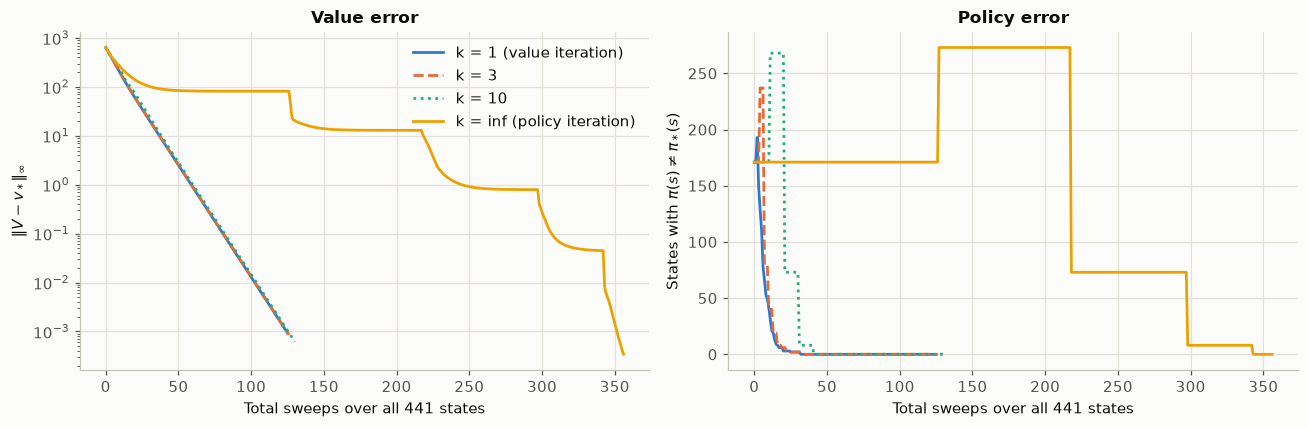

  k   | 개선 횟수 | 정책이 pi*가 된 스윕 | ||V-v*|| < 0.01 스윕 | 총 스윕 (||V-v*|| < 1e-3)
    1 |      124 |                 32 |                 103 |    125
    3 |       41 |                 34 |                 103 |    126
   10 |       12 |                 41 |                 104 |    130
  inf |        4 |                343 |                 343 |    356


In [9]:
def value_iteration(theta=1e-10, max_sweeps=10_000):
    """가치 반복: V <- max_a q(s, a).  (V, 스윕 수) 반환."""
    V = np.zeros((N, N))
    for sweep in range(1, max_sweeps + 1):
        V_new = q_values(V).max(axis=2)
        delta = np.abs(V_new - V).max()
        V = V_new
        if delta < theta:
            break
    return V, sweep


v_star, n_vi = value_iteration()
pi_star = ACTIONS[q_values(v_star).argmax(axis=2)]
print(f"value iteration: {n_vi} sweeps (theta = 1e-10)")
print("가치 반복의 탐욕 정책 == 정책 반복의 pi_4 ?", np.array_equal(pi_star, policies[4]))
print(f"max |v* - v_pi4| = {np.abs(v_star - v4).max():.2e}")
assert np.array_equal(pi_star, policies[4])


def modified_policy_iteration(k_eval, theta=1e-4, target=1e-3, max_sweeps=2000):
    """pi_0 = 0, V = 0 에서 시작해 [평가 스윕 k_eval번 -> 개선]을 반복 (k_eval=None: theta까지 평가).
    ||V - v*|| < target 이 되면 멈춤. 스윕마다 오차를 기록."""
    V = np.zeros((N, N))
    pi = np.zeros((N, N), dtype=int)
    log = {"sweep": [0], "err": [np.abs(V - v_star).max()], "wrong": [int((pi != pi_star).sum())]}
    n_improve, sweeps = 0, 0
    while sweeps < max_sweeps:
        j = 0
        while True:                                   # 평가
            V_new = backup_policy(V, pi)
            delta = np.abs(V_new - V).max()
            V = V_new
            sweeps += 1; j += 1
            log["sweep"].append(sweeps)
            log["err"].append(np.abs(V - v_star).max())
            log["wrong"].append(int((pi != pi_star).sum()))
            if (k_eval is not None and j >= k_eval) or (k_eval is None and delta < theta):
                break
        if log["err"][-1] < target:
            break
        pi = improve_policy(V, pi)                    # 개선
        n_improve += 1
    log = {key: np.array(val) for key, val in log.items()}
    log["n_improve"] = n_improve
    return log


runs = {k: modified_policy_iteration(k) for k in [1, 3, 10, None]}

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
STYLES = ["-", "--", ":", "-"]
for i, (k, log) in enumerate(runs.items()):
    label = "k = 1 (value iteration)" if k == 1 else ("k = inf (policy iteration)" if k is None else f"k = {k}")
    axes[0].semilogy(log["sweep"], log["err"], STYLES[i], color=PALETTE[i], lw=1.8, label=label)
    axes[1].plot(log["sweep"], log["wrong"], STYLES[i], color=PALETTE[i], lw=1.8, label=label)
axes[0].set_xlabel("Total sweeps over all 441 states"); axes[0].set_ylabel(r"$\|V - v_*\|_\infty$")
axes[0].set_title("Value error"); axes[0].legend(loc="upper right")
axes[1].set_xlabel("Total sweeps over all 441 states"); axes[1].set_ylabel(r"States with $\pi(s) \neq \pi_*(s)$")
axes[1].set_title("Policy error")
plt.tight_layout(); plt.show()

print("  k   | 개선 횟수 | 정책이 pi*가 된 스윕 | ||V-v*|| < 0.01 스윕 | 총 스윕 (||V-v*|| < 1e-3)")
for k, log in runs.items():
    first_opt = log["sweep"][np.argmax(log["wrong"] == 0)]
    first_001 = log["sweep"][np.argmax(log["err"] < 1e-2)]
    print(f" {str(k if k else 'inf'):>4} | {log['n_improve']:8d} | {first_opt:18d} | {first_001:19d} | {log['sweep'][-1]:6d}")

- **정책은 값보다 훨씬 먼저 수렴합니다.** 모든 방법에서 정책 오차(오른쪽)는 값 오차(왼쪽)가 작아지기 한참 전에 0이 됩니다.
- 평가를 $\theta=10^{-4}$까지 끝까지 하는 정책 반복($k=\infty$)은 개선 횟수는 가장 적지만(4번) 스윕 수는 가장 많습니다.
  왼쪽 그림의 평평한 구간은 $V$가 $v_*$가 아니라 **현재 정책의 가치** $v_{\pi_k}$로 수렴하느라 쓰는 스윕입니다.
  $k=3, 10$처럼 평가를 잘라도 같은 $\pi_*$에 약 10배 적은 스윕으로 도달합니다 — 이것이 **modified policy iteration**입니다.
- 가치 반복($k=1$)은 스윕 수는 비슷하지만 매 스윕이 11개 행동의 max를 계산하므로 한 스윕의 비용은 기대 백업보다 큽니다.
- 평가와 개선을 어떤 비율로 섞든 결국 $v_*,\pi_*$에 도달한다는 것이 **generalized policy iteration (GPI)**의 그림입니다.

## 5. 근사 동적 계획법: Fitted Value Iteration (Approximate Dynamic Programming)

슬라이드의 fitted value iteration을 그대로 구현합니다. 표 $V$(441개 값) 대신 파라미터 $\mathbf{w}$를 가진 함수
$\hat v(s,\mathbf{w}) = \mathbf{w}^\top\phi(s)$로 가치를 표현합니다. 특징 $\phi(s)$는 $x=n_1/20$, $y=n_2/20$의 차수 $\le d$ 다항식
($d=4$이면 15개)입니다. 매 반복 $k$마다

1. 상태 표본 $\tilde{\mathcal S}\subseteq\mathcal S$ (여기서는 100개)를 뽑고,
2. 각 표본에서 목표값 $\tilde v_k(s)=\max_a\big[\mathcal R^a_s+\gamma\sum_{s'}\mathcal P^a_{ss'}\hat v(s',\mathbf{w}_k)\big]$를 계산한 뒤,
3. 최소제곱 회귀로 $\mathbf{w}_{k+1}$을 맞춥니다.

degree | #params | max|v_hat - v*| | 탐욕 정책 == pi* 비율 | max_s (v* - v_{greedy})
     2 |       6 |            4.39 |                0.828 |    1.012
     3 |      10 |            4.08 |                0.916 |    0.366
     4 |      15 |            3.41 |                0.968 |    0.042


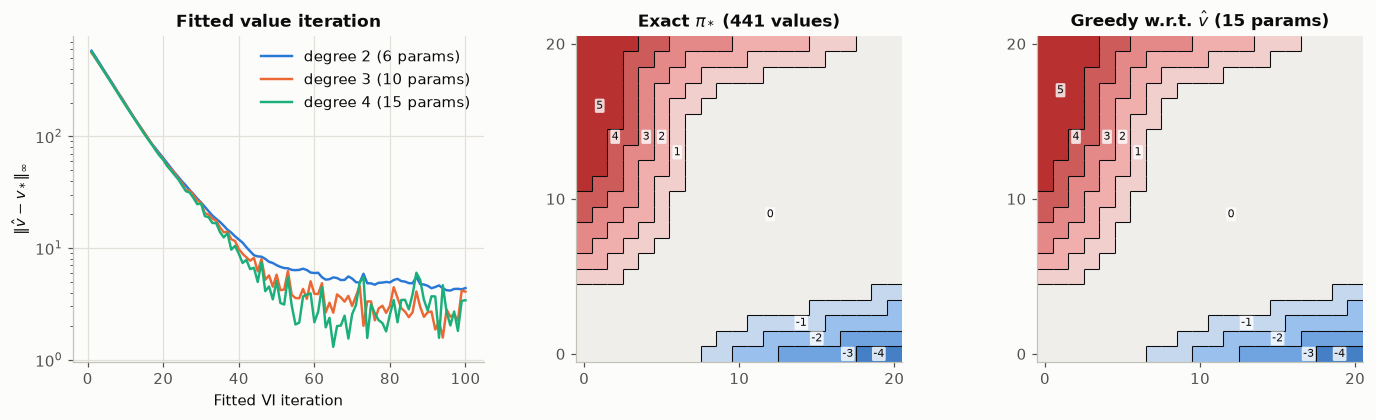

In [10]:
def poly_features(degree):
    """phi[n1, n2, :] = x^i y^j (i + j <= degree), x = n1/20, y = n2/20."""
    x = np.arange(N)[:, None] / MAX_CARS * np.ones((1, N))
    y = np.arange(N)[None, :] / MAX_CARS * np.ones((N, 1))
    return np.stack([x ** i * y ** j for i in range(degree + 1) for j in range(degree + 1 - i)], axis=-1)


def fitted_value_iteration(degree, n_samples=100, n_iters=100, seed=0):
    rng = np.random.default_rng(seed)
    phi = poly_features(degree)
    w = np.zeros(phi.shape[-1])
    errs = []
    for k in range(n_iters):
        v_hat = phi @ w                                   # 모든 상태에서의 근사값 (s' 기댓값 계산용)
        target = q_values(v_hat).max(axis=2)              # 벨만 최적 백업
        idx = rng.choice(N * N, size=n_samples, replace=False)
        X = phi.reshape(-1, phi.shape[-1])[idx]
        w = np.linalg.lstsq(X, target.reshape(-1)[idx], rcond=None)[0]
        errs.append(np.abs(phi @ w - v_star).max())
    return w, phi, np.array(errs)


fvi = {d: fitted_value_iteration(d) for d in [2, 3, 4]}
print("degree | #params | max|v_hat - v*| | 탐욕 정책 == pi* 비율 | max_s (v* - v_{greedy})")
for d, (w, phi, errs) in fvi.items():
    v_hat = phi @ w
    pi_hat = ACTIONS[q_values(v_hat).argmax(axis=2)]
    v_pi_hat, _ = evaluate_policy(pi_hat, v_star.copy(), theta=1e-8)
    print(f"{d:6d} | {phi.shape[-1]:7d} | {np.abs(v_hat - v_star).max():15.2f} | {np.mean(pi_hat == pi_star):20.3f} | {np.max(v_star - v_pi_hat):8.3f}")

fig = plt.figure(figsize=(13, 3.9))
ax = fig.add_subplot(1, 3, 1)
for i, (d, (w, phi, errs)) in enumerate(fvi.items()):
    ax.semilogy(np.arange(1, len(errs) + 1), errs, color=PALETTE[i], lw=1.6, label=f"degree {d} ({phi.shape[-1]} params)")
ax.set_xlabel("Fitted VI iteration"); ax.set_ylabel(r"$\|\hat v - v_*\|_\infty$")
ax.set_title("Fitted value iteration"); ax.legend()
w4, phi4, _ = fvi[4]
draw_car_policy(fig.add_subplot(1, 3, 2), pi_star, r"Exact $\pi_*$ (441 values)")
draw_car_policy(fig.add_subplot(1, 3, 3), ACTIONS[q_values(phi4 @ w4).argmax(axis=2)], r"Greedy w.r.t. $\hat v$ (15 params)")
plt.tight_layout(); plt.show()

15개 파라미터(차수 4)만으로도 오차가 $v_*$(420~640)의 1% 이하로 수렴하고, 그 탐욕 정책은 대부분의 상태에서 $\pi_*$와 같으며
다른 상태에서도 손실이 매우 작습니다(위 표의 마지막 열). 차수가 낮을수록 오차가 더 높은 곳에서 멈추고 탐욕 정책의 일치율도 떨어집니다.
다만 표본과 회귀를 쓰므로 오차가 단조롭게 줄지 않고 흔들리며, 일반적으로 fitted VI는 수렴이 보장되지 않습니다 —
이 주제는 가치 함수 근사(Week 07)에서 다시 다룹니다.

## 직접 해보기

설정을 바꾸면 "슬라이드와 비교"의 `assert`가 실패할 수 있습니다(원래 설정 전용 검사이므로 정상입니다).

1. **교재 연습문제 4.7**: (i) 1번 → 2번으로 1대는 무료로 옮길 수 있고, (ii) 밤사이 한 영업소에 10대를 넘게 두면 $\$4$의 추가 주차비가 듭니다.
   `COST`를 `MOVE_COST * np.where(ACTIONS > 0, ACTIONS - 1, -ACTIONS)`로 바꾸고, `q_values`/`backup_policy`에서
   아침 차량 수 `M1 > 10`, `M2 > 10`마다 4를 빼 보세요. 정책 모양이 어떻게 바뀌나요?
2. **평가 정밀도**: `evaluate_policy`의 `theta`를 `1e-1`, `10`으로 키워 정책 반복을 다시 돌려 보세요. 스윕 수는 얼마나 줄고, 최종 정책은 같은가요?
3. **할인율**: `GAMMA = 0.5` 또는 `0.99`로 바꾸면 차를 옮기는 영역이 넓어지나요 좁아지나요? 이유를 "미래 수익의 가치"로 설명해 보세요.
4. **Fitted VI**: `n_samples=20` 또는 `degree=6`으로 바꾸면 오차 곡선이 어떻게 달라지나요? 표본이 특징 수보다 적으면 어떤 일이 생길까요?